# 00 — Confronto di tutti i modelli su dataset reali

Confrontiamo i modelli delle esercitazioni 01-03 — **GaussianNB, MultinomialNB, BernoulliNB, KNN, SVM (RBF)** — su dataset reali di tipo diverso:

| Tipo | Dataset | Hugging Face | Kaggle (equivalente) |
|---|---|---|---|
| Testo (binario) | SMS Spam Collection | [ucirvine/sms_spam](https://huggingface.co/datasets/ucirvine/sms_spam) | [sms-spam-collection-dataset](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset) |
| Testo (6 classi) | Emotion (tweet) | [dair-ai/emotion](https://huggingface.co/datasets/dair-ai/emotion) | [emotions-dataset-for-nlp](https://www.kaggle.com/datasets/praveengovi/emotions-dataset-for-nlp) |
| Strutturato continuo | Breast Cancer Wisconsin (30 feature continue) | (da scikit-learn) | [breast-cancer-wisconsin-data](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data) |
| Strutturato misto (continuo + discreto) | Adult Census Income | [scikit-learn/adult-census-income](https://huggingface.co/datasets/scikit-learn/adult-census-income) | [adult-census-income](https://www.kaggle.com/datasets/uciml/adult-census-income) |
| Immagini | Fashion-MNIST (28x28, 10 classi) | [zalando-datasets/fashion_mnist](https://huggingface.co/datasets/zalando-datasets/fashion_mnist) | [fashionmnist](https://www.kaggle.com/datasets/zalando-research/fashionmnist) |

Usiamo le versioni su **Hugging Face** perché si scaricano con la libreria `datasets` **senza account né API key** (Kaggle richiede credenziali per l'API: i link sono forniti per riferimento).

**Come rendere il confronto equo**
- stesso split 70/30 stratificato, `random_state=42`;
- preprocessing adatto al tipo di dato, **appreso solo sul train** (pipeline → niente data leakage);
- metriche: accuracy, **macro-F1** (importante con classi sbilanciate), tempo di fit+predict.

> Per tenere i tempi ragionevoli i dataset grandi sono sotto-campionati (parametro `MAX_SAMPLES`).

## 0. Setup
Serve `datasets` di Hugging Face: `pip install datasets` (in Anaconda: `conda install -c conda-forge datasets`).

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, FunctionTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
MAX_SAMPLES = 8000   # massimo di campioni per dataset (train+test) -> aumenta se hai tempo/CPU

C:\Users\matti\workspace\Github\usr_exercises\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Funzioni di supporto

- `subsample`: campionamento stratificato per limitare i tempi.
- `evaluate`: addestra ogni modello (una `Pipeline` o un `GridSearchCV`), misura accuracy, macro-F1 e tempo, e raccoglie le predizioni per le matrici di confusione.

In [2]:
RESULTS = []      # lista di dict con le metriche
PREDS = {}        # (dataset, modello) -> (y_test, y_pred, class_names)

def subsample(X, y, n=MAX_SAMPLES):
    """Campione stratificato di al massimo n elementi (X può essere DataFrame, array o lista)."""
    if len(y) <= n:
        return X, y
    idx, _ = train_test_split(np.arange(len(y)), train_size=n, stratify=y, random_state=RANDOM_STATE)
    X_new = X.iloc[idx] if hasattr(X, "iloc") else (X[idx] if isinstance(X, np.ndarray) else [X[i] for i in idx])
    return X_new, np.asarray(y)[idx]

def evaluate(dataset, models, X, y, class_names):
    """Split 70/30 stratificato, fit di ogni modello, metriche e predizioni."""
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
    print(f"\n=== {dataset}: train={len(y_tr)}, test={len(y_te)}, classi={len(class_names)} ===")
    for name, model in models.items():
        t0 = time.perf_counter()
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_te)
        dt = time.perf_counter() - t0
        acc = accuracy_score(y_te, y_pred)
        f1 = f1_score(y_te, y_pred, average="macro")
        extra = f" (best {model.best_params_})" if hasattr(model, "best_params_") else ""
        print(f"{name:<14} acc={acc:.4f}  macroF1={f1:.4f}  tempo={dt:6.1f}s{extra}")
        RESULTS.append({"dataset": dataset, "modello": name, "accuracy": acc, "macro_F1": f1, "tempo_s": dt})
        PREDS[(dataset, name)] = (y_te, y_pred, class_names)

def knn_search():
    """KNN con K scelto per cross-validation (3-fold) sul solo train: coerente con l'esercitazione 02."""
    return GridSearchCV(KNeighborsClassifier(weights="distance", metric="euclidean"),
                        {"n_neighbors": [3, 5, 9, 15]}, cv=3, scoring="accuracy")

# Insieme di modelli per DATI NUMERICI DENSI (continui, misti codificati, immagini)
def numeric_models(binarize_thr=0.0):
    return {
        # GaussianNB: nessuno scaling necessario, ma lo scaler non lo danneggia
        "GaussianNB": make_pipeline(StandardScaler(), GaussianNB()),
        # MultinomialNB richiede feature >= 0 -> MinMaxScaler porta tutto in [0, 1]
        "MultinomialNB": make_pipeline(MinMaxScaler(), MultinomialNB()),
        # BernoulliNB binarizza le feature: con dati standardizzati la soglia 0 = "sopra/sotto la media"
        "BernoulliNB": make_pipeline(StandardScaler(), BernoulliNB(binarize=binarize_thr)),
        "KNN": make_pipeline(StandardScaler(), knn_search()),
        "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE)),
    }

## 2. Dataset strutturato continuo — Breast Cancer Wisconsin
30 feature continue (misure dei nuclei cellulari), classificazione binaria maligno/benigno. Dataset piccolo (569 righe): ottimo per vedere quanto contano scaling e assunzioni gaussiane.

In [3]:
cancer = load_breast_cancer()
X_bc, y_bc = cancer.data, cancer.target
evaluate("Breast Cancer (continuo)", numeric_models(), X_bc, y_bc, list(cancer.target_names))


=== Breast Cancer (continuo): train=398, test=171, classi=2 ===
GaussianNB     acc=0.9357  macroF1=0.9307  tempo=   0.0s
MultinomialNB  acc=0.8363  macroF1=0.8021  tempo=   0.0s
BernoulliNB    acc=0.9415  macroF1=0.9380  tempo=   0.0s
KNN            acc=0.9649  macroF1=0.9618  tempo=   0.2s
SVM (RBF)      acc=0.9766  macroF1=0.9750  tempo=   0.0s


## 3. Dataset strutturato misto — Adult Census Income
Predire se il reddito supera 50K$. Mix di feature **continue** (`age`, `hours.per.week`, ...) e **discrete/categoriche** (`workclass`, `education`, `occupation`, ...), con valori mancanti codificati come `?`. Classi sbilanciate (~76% / 24%): qui il macro-F1 è più informativo dell'accuracy.

Preprocessing con `ColumnTransformer` (dentro la pipeline, quindi appreso solo sul train):
- numeriche → `StandardScaler`
- categoriche → `OneHotEncoder` (il `?` diventa semplicemente una categoria)

In [4]:
adult = load_dataset("scikit-learn/adult-census-income")["train"].to_pandas()
y_ad = (adult["income"].str.strip() == ">50K").astype(int).values
X_ad = adult.drop(columns=["income", "fnlwgt"])    # fnlwgt = peso di campionamento del censimento, non informativo
X_ad, y_ad = subsample(X_ad, y_ad)

num_cols = X_ad.select_dtypes("number").columns.tolist()
cat_cols = X_ad.select_dtypes(exclude="number").columns.tolist()
print("Numeriche:", num_cols, "\nCategoriche:", cat_cols)
print("Frazione classe >50K:", y_ad.mean().round(3))

def adult_models():
    prep = lambda scaler: ColumnTransformer([
        ("num", scaler, num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)])
    return {
        "GaussianNB": make_pipeline(prep(StandardScaler()), GaussianNB()),
        "MultinomialNB": make_pipeline(prep(MinMaxScaler()), MultinomialNB()),
        "BernoulliNB": make_pipeline(prep(StandardScaler()), BernoulliNB(binarize=0.0)),
        "KNN": make_pipeline(prep(StandardScaler()), knn_search()),
        "SVM (RBF)": make_pipeline(prep(StandardScaler()), SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE)),
    }

evaluate("Adult Income (misto)", adult_models(), X_ad, y_ad, ["<=50K", ">50K"])

Numeriche: ['age', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week'] 
Categoriche: ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']
Frazione classe >50K: 0.241

=== Adult Income (misto): train=5600, test=2400, classi=2 ===
GaussianNB     acc=0.3396  macroF1=0.3279  tempo=   0.1s
MultinomialNB  acc=0.7950  macroF1=0.7489  tempo=   0.0s
BernoulliNB    acc=0.7892  macroF1=0.7464  tempo=   0.0s


KNN            acc=0.8383  macroF1=0.7712  tempo=   1.0s


SVM (RBF)      acc=0.8596  macroF1=0.7898  tempo=   1.0s


## 4. Testo — SMS Spam (binario) ed Emotion (6 classi)

Rappresentazioni del testo:
- **Conteggi** (`CountVectorizer`) → `MultinomialNB`
- **Binarie** (`CountVectorizer(binary=True)`) → `BernoulliNB`
- **TF-IDF** (pesa le parole rare e normalizza la lunghezza) → KNN (distanza coseno) e SVM
- **TF-IDF + `TruncatedSVD`** (100 componenti, densa) → `GaussianNB` (che non accetta matrici sparse)

Il vocabolario viene appreso solo sul train, dentro la pipeline.

In [5]:
def text_models():
    return {
        "GaussianNB": make_pipeline(TfidfVectorizer(), TruncatedSVD(100, random_state=RANDOM_STATE), GaussianNB()),
        "MultinomialNB": make_pipeline(CountVectorizer(), MultinomialNB(alpha=1.0)),
        "BernoulliNB": make_pipeline(CountVectorizer(binary=True), BernoulliNB(alpha=1.0)),
        "KNN": make_pipeline(
            TfidfVectorizer(),
            GridSearchCV(KNeighborsClassifier(weights="distance", metric="cosine", algorithm="brute"),
                         {"n_neighbors": [3, 5, 9, 15]}, cv=3)),
        "SVM (RBF)": make_pipeline(TfidfVectorizer(), SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE)),
    }

# --- SMS Spam ---
sms = load_dataset("ucirvine/sms_spam")["train"]
X_sms, y_sms = subsample(list(sms["sms"]), np.array(sms["label"]))
evaluate("SMS Spam (testo, 2 classi)", text_models(), X_sms, y_sms, ["ham", "spam"])


=== SMS Spam (testo, 2 classi): train=3901, test=1673, classi=2 ===


GaussianNB     acc=0.8362  macroF1=0.7396  tempo=   0.6s
MultinomialNB  acc=0.9839  macroF1=0.9643  tempo=   0.0s
BernoulliNB    acc=0.9779  macroF1=0.9487  tempo=   0.0s


KNN            acc=0.9791  macroF1=0.9521  tempo=   0.6s


SVM (RBF)      acc=0.9821  macroF1=0.9592  tempo=   1.1s


In [6]:
# --- Emotion (unione di train/validation/test originali, poi nostro split 70/30) ---
emo = load_dataset("dair-ai/emotion")
emo_names = emo["train"].features["label"].names
texts = sum([list(emo[s]["text"]) for s in emo], [])
labels = np.concatenate([np.array(emo[s]["label"]) for s in emo])
X_emo, y_emo = subsample(texts, labels)
evaluate("Emotion (testo, 6 classi)", text_models(), X_emo, y_emo, emo_names)


=== Emotion (testo, 6 classi): train=5600, test=2400, classi=6 ===


GaussianNB     acc=0.3246  macroF1=0.2259  tempo=   0.7s
MultinomialNB  acc=0.6837  macroF1=0.4617  tempo=   0.1s
BernoulliNB    acc=0.5996  macroF1=0.2857  tempo=   0.1s


KNN            acc=0.7004  macroF1=0.6124  tempo=   1.4s


SVM (RBF)      acc=0.7262  macroF1=0.5855  tempo=   8.6s


## 5. Immagini — Fashion-MNIST
Immagini 28x28 in scala di grigi (10 classi di capi d'abbigliamento), appiattite in vettori di 784 pixel e portate in [0, 1].
I modelli lavorano su pixel grezzi (nessuna convoluzione): è una baseline "classica" da confrontare poi con le reti neurali del corso.

- `BernoulliNB` binarizza i pixel con soglia 0.5 (inchiostro / non inchiostro);
- `MultinomialNB` usa le intensità come "conteggi";
- `GaussianNB` modella ogni pixel come gaussiana (assunzione debole su immagini: i pixel sono molto correlati).

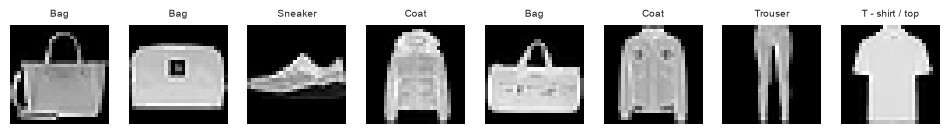


=== Fashion-MNIST (immagini): train=5600, test=2400, classi=10 ===
GaussianNB     acc=0.6471  macroF1=0.6305  tempo=   0.1s


MultinomialNB  acc=0.6683  macroF1=0.6374  tempo=   0.4s


BernoulliNB    acc=0.6683  macroF1=0.6666  tempo=   0.3s


KNN            acc=0.8033  macroF1=0.8046  tempo=   2.1s


SVM (RBF)      acc=0.8621  macroF1=0.8606  tempo=   4.8s


In [7]:
fm = load_dataset("zalando-datasets/fashion_mnist")
fm_names = fm["train"].features["label"].names

def to_array(split, n):
    # prende n immagini casuali (seed fisso) e le appiattisce
    rng = np.random.RandomState(RANDOM_STATE)
    idx = rng.choice(len(fm[split]), n, replace=False)
    sub = fm[split].select(idx)
    X = np.stack([np.asarray(im, dtype=np.float32).ravel() / 255.0 for im in sub["image"]])
    return X, np.array(sub["label"])

Xa, ya = to_array("train", MAX_SAMPLES)
X_fm, y_fm = Xa, ya

# Pipeline: per le immagini non standardizziamo (i pixel hanno già la stessa scala [0,1]);
# StandardScaler per KNN/SVM resta utile per equalizzare la varianza dei singoli pixel.
def image_models():
    return {
        "GaussianNB": make_pipeline(GaussianNB(var_smoothing=1e-3)),
        "MultinomialNB": make_pipeline(MultinomialNB()),
        "BernoulliNB": make_pipeline(BernoulliNB(binarize=0.5)),
        "KNN": make_pipeline(StandardScaler(), knn_search()),
        "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE)),
    }

# Qualche esempio
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, img, lab in zip(axes, X_fm[:8], y_fm[:8]):
    ax.imshow(img.reshape(28, 28), cmap="gray"); ax.set_title(fm_names[lab], fontsize=7); ax.axis("off")
plt.show()

evaluate("Fashion-MNIST (immagini)", image_models(), X_fm, y_fm, fm_names)

## 6. Risultati complessivi

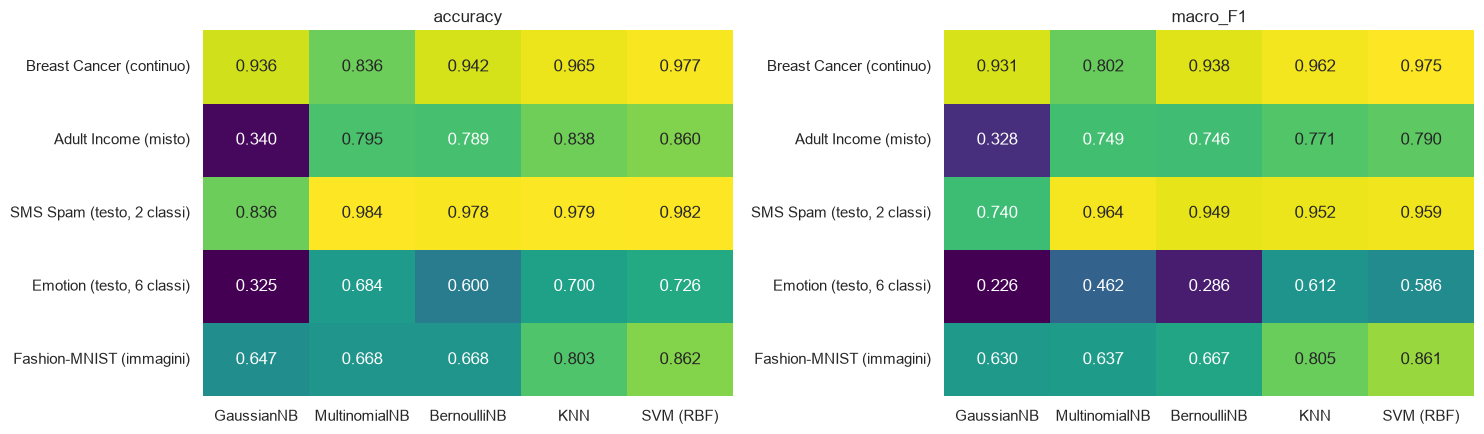

,dataset,modello,accuracy,macro_F1,tempo_s
0,Breast Cancer (continuo),GaussianNB,0.9357,0.9307,0.0027
1,Breast Cancer (continuo),MultinomialNB,0.8363,0.8021,0.0029
2,Breast Cancer (continuo),BernoulliNB,0.9415,0.9380,0.0025
3,Breast Cancer (continuo),KNN,0.9649,0.9618,0.1570
4,Breast Cancer (continuo),SVM (RBF),0.9766,0.9750,0.0050
5,Adult Income (misto),GaussianNB,0.3396,0.3279,0.0645
6,Adult Income (misto),MultinomialNB,0.7950,0.7489,0.0345
7,Adult Income (misto),BernoulliNB,0.7892,0.7464,0.0388
8,Adult Income (misto),KNN,0.8383,0.7712,0.9750
9,Adult Income (misto),SVM (RBF),0.8596,0.7898,1.0028


In [8]:
res = pd.DataFrame(RESULTS)
order_ds = list(dict.fromkeys(res["dataset"]))
order_m = ["GaussianNB", "MultinomialNB", "BernoulliNB", "KNN", "SVM (RBF)"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, metric in zip(axes, ["accuracy", "macro_F1"]):
    piv = res.pivot(index="dataset", columns="modello", values=metric).loc[order_ds, order_m]
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis", ax=ax, cbar=False)
    ax.set_title(metric); ax.set_ylabel(""); ax.set_xlabel("")
plt.tight_layout(); plt.show()

display(res.round(4))

Ranking medio (macro-F1, più basso = meglio):
 modello
SVM (RBF)        1.4
KNN              2.0
MultinomialNB    3.2
BernoulliNB      3.6
GaussianNB       4.8
Name: rank_F1, dtype: float64


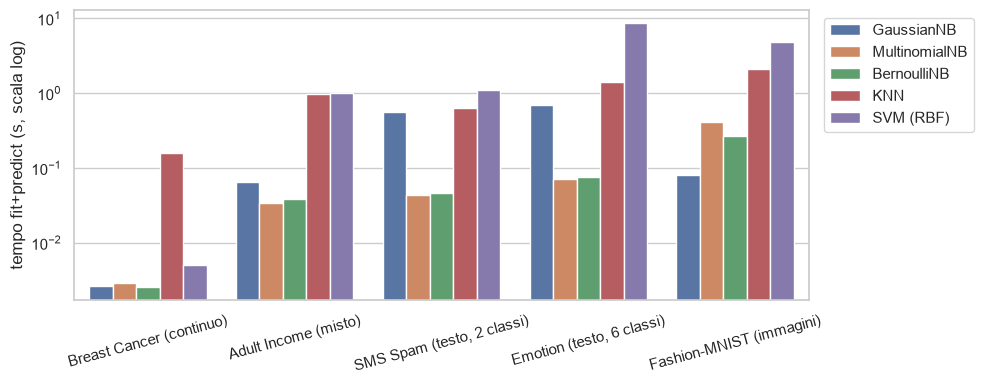

In [9]:
# Ranking medio (1 = migliore) sul macro-F1, su tutti i dataset
res["rank_F1"] = res.groupby("dataset")["macro_F1"].rank(ascending=False)
ranking = res.groupby("modello")["rank_F1"].mean().sort_values()
print("Ranking medio (macro-F1, più basso = meglio):\n", ranking.round(2))

# Tempi di calcolo
plt.figure(figsize=(10, 4))
sns.barplot(data=res, x="dataset", y="tempo_s", hue="modello", hue_order=order_m)
plt.yscale("log"); plt.ylabel("tempo fit+predict (s, scala log)"); plt.xlabel("")
plt.xticks(rotation=15); plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

## 7. Matrici di confusione del miglior modello per dataset

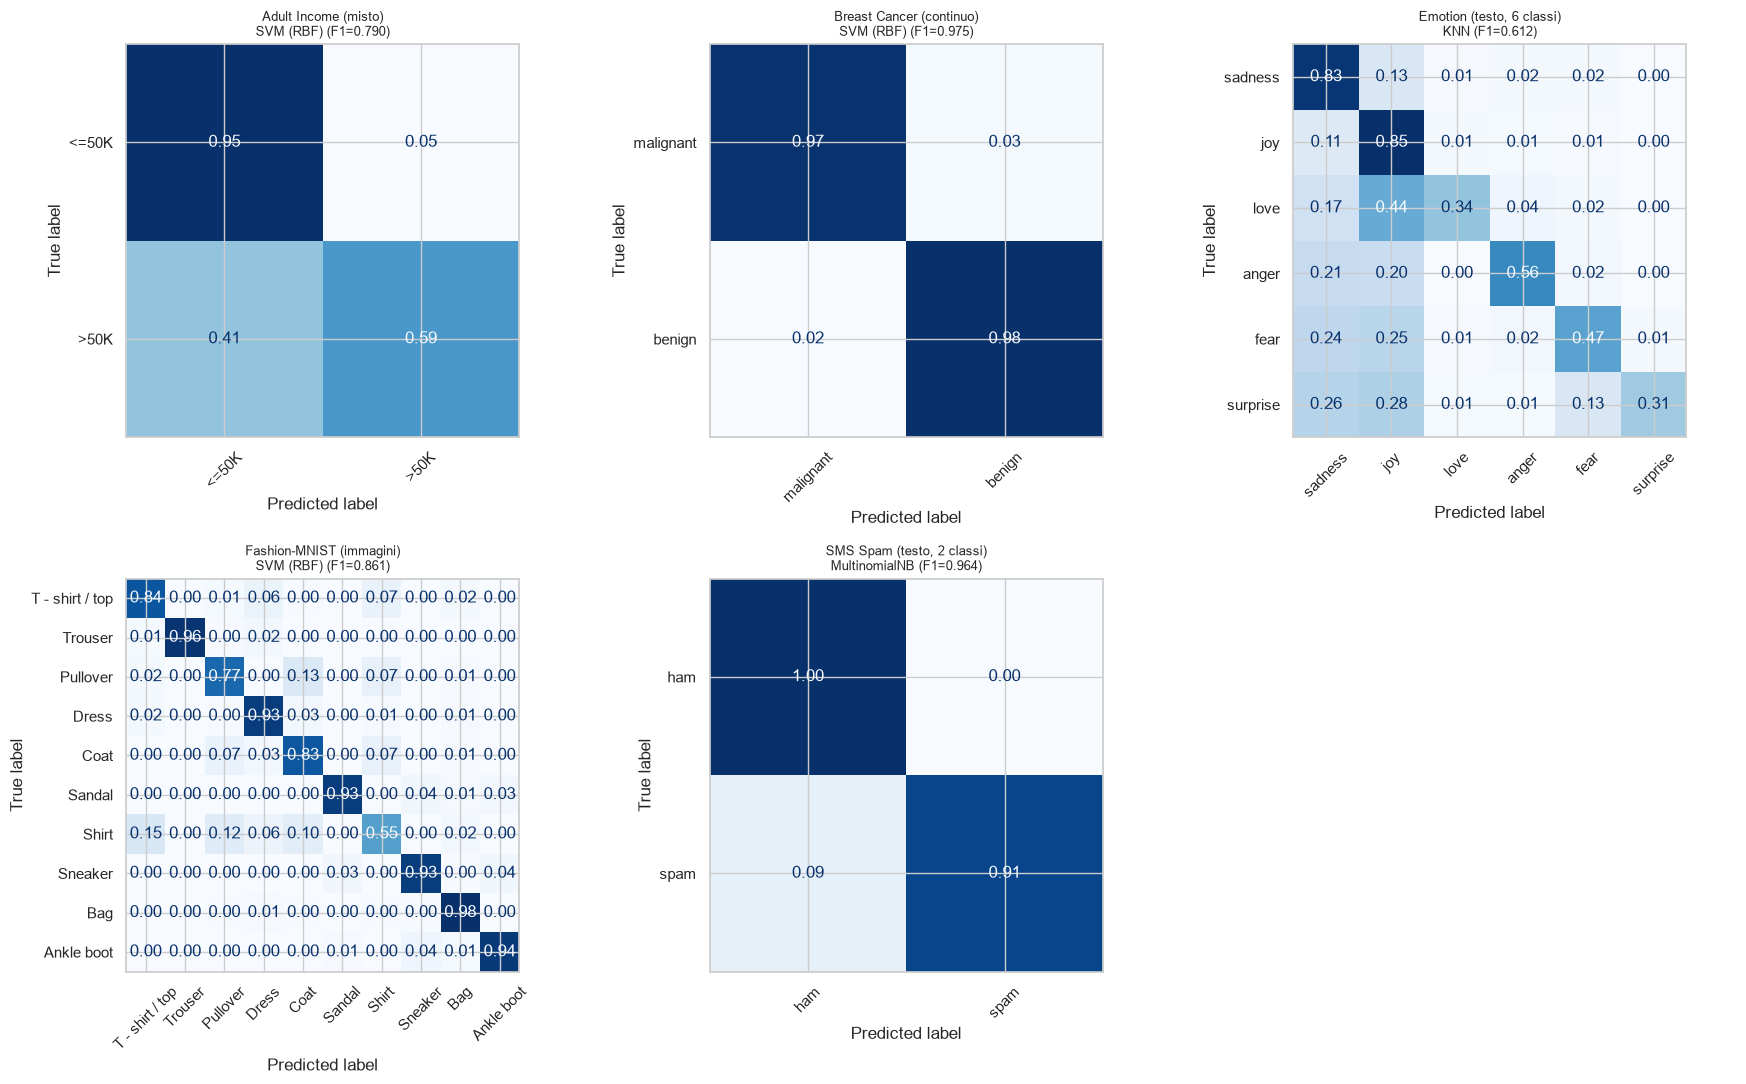

In [10]:
best = res.loc[res.groupby("dataset")["macro_F1"].idxmax()]
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, (_, r) in zip(axes.ravel(), best.iterrows()):
    y_te, y_pred, names = PREDS[(r["dataset"], r["modello"])]
    ConfusionMatrixDisplay.from_predictions(y_te, y_pred, display_labels=names, ax=ax, cmap="Blues",
                                            colorbar=False, xticks_rotation=45, normalize="true", values_format=".2f")
    ax.set_title(f"{r['dataset']}\n{r['modello']} (F1={r['macro_F1']:.3f})", fontsize=9)
for ax in axes.ravel()[len(best):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 8. Come leggere i risultati

Confronta questi risultati con le aspettative teoriche (dopo aver eseguito il notebook, verifica quali si confermano):

- **Testo:** `MultinomialNB`/`BernoulliNB` sono nati per conteggi e presenza di parole → di solito competitivi con SVM, ma molto più veloci. `GaussianNB` (su TF-IDF+SVD) è la scelta meno naturale.
- **Dati continui (Breast Cancer):** SVM e KNN con scaling tendono a vincere; `GaussianNB` è un'ottima baseline per costo/prestazioni.
- **Dati misti (Adult):** con classi sbilanciate guarda il macro-F1. Nota il crollo di `GaussianNB` (~0.34 di accuracy, peggio del classificatore "sempre <=50K"): le colonne one-hot sono binarie e quasi costanti per classe, quindi la gaussiana stimata ha varianze minuscole e probabilità degeneri. `MultinomialNB`/`BernoulliNB` gestiscono meglio le feature discrete; inoltre l'indipendenza è violata da variabili correlate (es. `education` / `education.num`).
- **Immagini (pixel grezzi):** SVM RBF e KNN battono nettamente i NB, perché i pixel vicini sono fortemente correlati (viola l'ipotesi "naïve"); per fare meglio servono CNN.
- **Tempi:** NB addestra in frazioni di secondo; KNN costa in *predizione*; SVM costa in *addestramento* (≈ quadratico nei campioni).

**Esperimenti suggeriti:** aumenta `MAX_SAMPLES`; fai variare `C`/`gamma` dell'SVM con `GridSearchCV`; sostituisci `ucirvine/sms_spam` con `fancyzhx/ag_news` o `stanfordnlp/imdb` per testi più lunghi; prova `cifar10` (immagini a colori, molto più difficili con pixel grezzi).